Tema 2

Setul de date Fruits

In [1]:
!pip install kaggle

In [2]:
!kaggle datasets download -d moltean/fruits # https://www.kaggle.com/datasets/moltean/fruits/data

Dataset URL: https://www.kaggle.com/datasets/moltean/fruits
License(s): CC-BY-SA-4.0
 99% 955M/964M [00:13<00:00, 59.5MB/s]
100% 964M/964M [00:13<00:00, 76.9MB/s]


In [3]:
import zipfile

with zipfile.ZipFile("fruits.zip", 'r') as zip_ref:
    zip_ref.extractall("fruits_data")

In [4]:
import os
import cv2
import random
from PIL import Image
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict
from skimage.feature import hog
from sklearn.decomposition import PCA

from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, log_loss
from sklearn.preprocessing import StandardScaler

import time
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms
from torch.utils.data import DataLoader, TensorDataset, Dataset

In [5]:
data_dir = os.path.join("fruits_data", "fruits-360_dataset_100x100")
data_dir = os.path.join(data_dir, "fruits-360")
print(data_dir)

training_dir = os.path.join(data_dir, "Training")
test_dir = os.path.join(data_dir, "Test")

print(training_dir)
print(test_dir)

fruits_data/fruits-360_dataset_100x100/fruits-360
fruits_data/fruits-360_dataset_100x100/fruits-360/Training
fruits_data/fruits-360_dataset_100x100/fruits-360/Test


In [6]:
CLASSES = []
TRAINING_IMAGES = []
TEST_IMAGES = []

for dir_name in os.listdir(training_dir):
    CLASSES.append(dir_name)

print(f"Numărul claselor: {len(CLASSES)}")

Numărul claselor: 141


In [7]:
def get_images(directory):
    images = []

    for class_name in CLASSES:
        class_directory = os.path.join(directory, class_name)

        for img in os.listdir(class_directory):
            img_file = os.path.join(class_directory, img)
            images.append((img_file, class_name))

    return images

In [17]:
TRAINING_IMAGES = get_images(training_dir)
print(f"Sunt {len(TRAINING_IMAGES)} în setul de date de antrenare!")

TEST_IMAGES = get_images(test_dir)
print(f"Sunt {len(TEST_IMAGES)} în setul de date de testare!")

Sunt 70491 în setul de date de antrenare!
Sunt 23619 în setul de date de testare!


1. Extragerea de atribute

Atribute HOG

In [9]:
def extract_hog_features(image):
    image = cv2.resize(image, (32, 32))
    gray_image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    features = hog(gray_image, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=False)

    return features


In [10]:
def hog_extraction(images):
    hog_features = []
    for img, label in tqdm(images, desc="Extracting HOG Features"):
        img = cv2.imread(img)
        image = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        features = extract_hog_features(image)
        hog_features.append(features)

    return hog_features

In [11]:
hog_features_train = hog_extraction(TRAINING_IMAGES)
hog_features_test = hog_extraction(TEST_IMAGES)

Extracting HOG Features: 100%|██████████| 23619/23619 [00:19<00:00, 1237.95it/s]


In [12]:
print("HOG Features Train Size:", len(hog_features_train))
print("HOG Features Test Size:", len(hog_features_test))

HOG Features Train Size: 70491
HOG Features Test Size: 23619


Atribute ORB

In [13]:
def extract_orb_features_and_images(image):
    gray_image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    orb = cv2.ORB_create()
    keypoints = orb.detect(gray_image)
    keypoints, descriptors = orb.compute(gray_image, keypoints)

    copy_image = np.copy(image)

    # generare imagini pentru vizualizarea punctelor cheie
    keypoints_image = cv2.drawKeypoints(copy_image, keypoints, None, color = (0, 255, 0))
    orb_image = cv2.drawKeypoints(image, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

    return keypoints, descriptors, orb_image, keypoints_image

In [14]:
def orb_extraction(images):
    orb_features = []
    orb_keypoints = []
    skipped_inddices = []

    for i, (img, label) in tqdm(enumerate(images), desc="Extracting ORB Features"):
        image = cv2.imread(img)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        keypoints, descriptors, orb_image, _ = extract_orb_features_and_images(image)

        if descriptors is not None:
            orb_features.append(descriptors)
            orb_keypoints.append(keypoints)
        else:
            skipped_inddices.append(i)

    return orb_features, orb_keypoints, skipped_inddices

In [15]:
orb_features_train, orb_keypoints_train, skipped_indices_train = orb_extraction(TRAINING_IMAGES)
orb_features_test, orb_keypoints_test, skipped_indices_test = orb_extraction(TEST_IMAGES)

Extracting ORB Features: 70491it [01:00, 1171.66it/s]
Extracting ORB Features: 23619it [00:22, 1027.20it/s]


In [16]:
print("ORB Features Train Size:", len(orb_features_train))
print("ORB Features Test Size:", len(orb_features_test))

ORB Features Train Size: 55526
ORB Features Test Size: 18059


I. MLP pe atributele extrase

In [18]:
hog_max = 0

for features in hog_features_train:
    if len(features) > hog_max:
        hog_max = len(features)

print(hog_max)

324


In [19]:
hog_max = 0

for features in hog_features_test:
    if len(features) > hog_max:
        hog_max = len(features)

print(hog_max)

324


In [20]:
orb_max = 0

for features in orb_features_train:
    if len(features) > orb_max:
        orb_max = len(features)

print(orb_max)

119


In [21]:
orb_max = 0

for features in orb_features_test:
    if len(features) > orb_max:
        orb_max = len(features)

print(orb_max)

121


In [22]:
X_train = [img[0] for img in TRAINING_IMAGES]
y_train = [img[1] for img in TRAINING_IMAGES]

X_test = [img[0] for img in TEST_IMAGES]
y_test = [img[1] for img in TEST_IMAGES]

HOG

In [23]:
hog_selector = SelectPercentile(score_func=f_classif, percentile=39)
X_train_hog_reduced = hog_selector.fit_transform(hog_features_train, y_train)
X_test_hog_reduced = hog_selector.transform(hog_features_test)

In [24]:
hog_max = 0

for features in X_train_hog_reduced:
    if len(features) > hog_max:
        hog_max = len(features)

print("Numarul de atribute maxim dupa aplicarea Select Percentile este", hog_max)

Numarul de atribute maxim dupa aplicarea Select Percentile este 126


In [25]:
# standardizare a datelor
scaler = StandardScaler()
X_train_hog = scaler.fit_transform(X_train_hog_reduced)
X_test_hog = scaler.transform(X_test_hog_reduced)

# tranformare valori => media = 0 si deviatia standard = 1
# functiile de activare sunt sensibile la scale mari ale intrarilor
# imbunatatire acuratete

In [26]:
# modelul MLP
mlp_hog = MLPClassifier(
    hidden_layer_sizes=(128, 128),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=20,
    random_state=42,
    verbose=True
)

train_accuracy_curve_hog = []
test_accuracy_curve_hog = []
train_loss_curve_hog = []
test_loss_curve_hog = []

start_time = time.time()

for epoch in range(mlp_hog.max_iter):
    mlp_hog.partial_fit(X_train_hog, y_train, classes=np.unique(y_train))

    train_accuracy_curve_hog.append(accuracy_score(y_train, mlp_hog.predict(X_train_hog)))
    test_accuracy_curve_hog.append(accuracy_score(y_test, mlp_hog.predict(X_test_hog)))

    train_loss_curve_hog.append(mlp_hog.loss_)
    test_loss_curve_hog.append(log_loss(y_test, mlp_hog.predict_proba(X_test_hog)))

    print(f"Epoch {epoch + 1}/{mlp_hog.max_iter}, Train Loss: {train_loss_curve_hog[-1]:.4f}, Test Loss: {test_loss_curve_hog[-1]:.4f}, Train Acc: {train_accuracy_curve_hog[-1] * 100:.2f}%, Test Acc: {test_accuracy_curve_hog[-1] * 100:.4f}%")

end_time = time.time()

Iteration 1, loss = 1.58581282
Epoch 1/20, Train Loss: 1.5858, Test Loss: 1.6170, Train Acc: 80.02%, Test Acc: 59.1177%
Iteration 1, loss = 0.51652294
Epoch 2/20, Train Loss: 0.5165, Test Loss: 1.4015, Train Acc: 90.23%, Test Acc: 66.0655%
Iteration 1, loss = 0.29839683
Epoch 3/20, Train Loss: 0.2984, Test Loss: 1.3391, Train Acc: 93.78%, Test Acc: 69.7235%
Iteration 1, loss = 0.19912067
Epoch 4/20, Train Loss: 0.1991, Test Loss: 1.3290, Train Acc: 95.51%, Test Acc: 71.8574%
Iteration 1, loss = 0.14393187
Epoch 5/20, Train Loss: 0.1439, Test Loss: 1.3557, Train Acc: 96.60%, Test Acc: 72.8820%
Iteration 1, loss = 0.10891235
Epoch 6/20, Train Loss: 0.1089, Test Loss: 1.4059, Train Acc: 97.39%, Test Acc: 73.6060%
Iteration 1, loss = 0.08599497
Epoch 7/20, Train Loss: 0.0860, Test Loss: 1.4737, Train Acc: 97.70%, Test Acc: 74.0040%
Iteration 1, loss = 0.07602461
Epoch 8/20, Train Loss: 0.0760, Test Loss: 1.5117, Train Acc: 97.97%, Test Acc: 74.4147%
Iteration 1, loss = 0.06187937
Epoch 9/2

In [27]:
training_time = end_time - start_time
print(f"Timpul total de antrenare pentru MLP (HOG): {training_time:.2f} secunde")

Timpul total de antrenare pentru MLP (HOG): 93.90 secunde


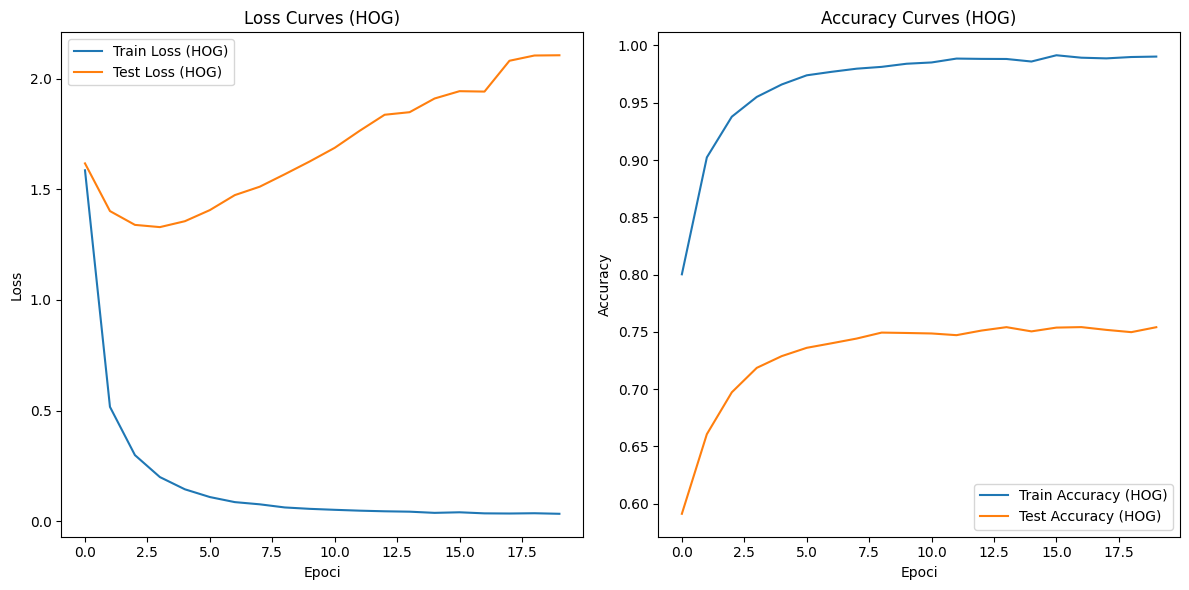

In [29]:
plt.figure(figsize=(12, 6))

# curba de loss
plt.subplot(1, 2, 1)
plt.plot(train_loss_curve_hog, label='Train Loss (HOG)')
plt.plot(test_loss_curve_hog, label='Test Loss (HOG)')
plt.title('Loss Curves (HOG)')
plt.xlabel('Epoci')
plt.ylabel('Loss')
plt.legend()

# curba de accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accuracy_curve_hog, label='Train Accuracy (HOG)')
plt.plot(test_accuracy_curve_hog, label='Test Accuracy (HOG)')
plt.title('Accuracy Curves (HOG)')
plt.xlabel('Epoci')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [80]:
# raport de clasificare pentru modelul MLP (HOG)
y_test_pred_hog = mlp_hog.predict(X_test_hog)
print("Raport de clasificare pentru modelul MLP (HOG)")
print(classification_report(y_test, y_test_pred_hog))

Raport de clasificare pentru modelul MLP (HOG)
                       precision    recall  f1-score   support

              Apple 6       0.71      0.98      0.83       157
     Apple Braeburn 1       0.65      0.62      0.64       164
 Apple Crimson Snow 1       0.71      0.76      0.74       148
       Apple Golden 1       0.58      0.62      0.60       160
       Apple Golden 2       0.78      0.71      0.75       164
       Apple Golden 3       0.54      0.65      0.59       161
 Apple Granny Smith 1       0.86      0.72      0.78       164
    Apple Pink Lady 1       0.77      0.72      0.75       152
          Apple Red 1       0.62      0.54      0.58       164
          Apple Red 2       0.78      0.67      0.72       164
          Apple Red 3       0.79      0.61      0.69       144
Apple Red Delicious 1       0.79      0.89      0.84       166
   Apple Red Yellow 1       0.60      0.43      0.50       164
   Apple Red Yellow 2       0.86      0.82      0.84       219
       

ORB

In [31]:
y_train_orb = y_train
y_train_orb = np.delete(y_train_orb, skipped_indices_train)

In [32]:
y_test_orb = y_test
y_test_orb = np.delete(y_test_orb, skipped_indices_test)

In [33]:
max_len = max(
    max(len(descriptors) for descriptors in orb_features_train),
    max(len(descriptors) for descriptors in orb_features_test)
)

In [34]:
padded_orb_features_train = [
    np.pad(descriptors, ((0, max_len - len(descriptors)), (0, 0)), 'constant')
    for descriptors in orb_features_train
]

In [35]:
padded_orb_features_test = [
    np.pad(descriptors, ((0, max_len - len(descriptors)), (0, 0)), 'constant')
    for descriptors in orb_features_test
]

In [36]:
reshaped_orb_features_train = np.array([descriptors.flatten() for descriptors in padded_orb_features_train])
reshaped_orb_features_test = np.array([descriptors.flatten() for descriptors in padded_orb_features_test])

In [39]:
selector_orb = SelectPercentile(score_func=f_classif, percentile=90)
X_train_orb_reduced = selector_orb.fit_transform(reshaped_orb_features_train, y_train_orb)
X_test_orb_reduced = selector_orb.transform(reshaped_orb_features_test)

/usr/local/lib/python3.10/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [3808 3809 3810 3811 3812 3813 3814 3815 3816 3817 3818 3819 3820 3821
 3822 3823 3824 3825 3826 3827 3828 3829 3830 3831 3832 3833 3834 3835
 3836 3837 3838 3839 3840 3841 3842 3843 3844 3845 3846 3847 3848 3849
 3850 3851 3852 3853 3854 3855 3856 3857 3858 3859 3860 3861 3862 3863
 3864 3865 3866 3867 3868 3869 3870 3871] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.10/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


In [40]:
# standardizare a datelor
scaler_orb = StandardScaler()
X_train_orb = scaler_orb.fit_transform(X_train_orb_reduced)
X_test_orb = scaler_orb.transform(X_test_orb_reduced)

# tranformare valori => media = 0 si deviatia standard = 1
# functiile de activare sunt sensibile la scale mari ale intrarilor
# imbunatatire acuratete

In [41]:
train_classes = np.unique(y_train_orb)
test_classes = np.unique(y_test_orb)

common_classes = np.intersect1d(train_classes, test_classes)

In [42]:
train_indices = np.where(np.isin(y_train_orb, common_classes))[0]
X_train_orb_filtered = X_train_orb[train_indices]
y_train_orb_filtered = y_train_orb[train_indices]

In [43]:
test_indices = np.where(np.isin(y_test_orb, common_classes))[0]
X_test_orb_filtered = X_test_orb[test_indices]
y_test_orb_filtered = y_test_orb[test_indices]

In [45]:
# modelul MLP
mlp_orb = MLPClassifier(
    hidden_layer_sizes=(128, 128),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=20,
    random_state=42,
    verbose=True
)

train_accuracy_curve_orb = []
test_accuracy_curve_orb = []
train_loss_curve_orb = []
test_loss_curve_orb = []

start_time = time.time()

for epoch in range(mlp_orb.max_iter):
    mlp_orb.partial_fit(X_train_orb_filtered, y_train_orb_filtered, classes=np.unique(y_train_orb_filtered))

    train_accuracy_curve_orb.append(accuracy_score(y_train_orb_filtered, mlp_orb.predict(X_train_orb_filtered)))
    test_accuracy_curve_orb.append(accuracy_score(y_test_orb_filtered, mlp_orb.predict(X_test_orb_filtered)))

    train_loss_curve_orb.append(mlp_orb.loss_)
    test_loss_curve_orb.append(log_loss(y_test_orb_filtered, mlp_orb.predict_proba(X_test_orb_filtered)))

    print(f"Epoch {epoch + 1}/{mlp_orb.max_iter}, Train Loss: {train_loss_curve_orb[-1]:.4f}, Test Loss: {test_loss_curve_orb[-1]:.4f}, Train Acc: {train_accuracy_curve_orb[-1] * 100:.2f}%, Test Acc: {test_accuracy_curve_orb[-1] * 100:.4f}%")

end_time = time.time()

Iteration 1, loss = 3.49490213
Epoch 1/20, Train Loss: 3.4949, Test Loss: 3.7254, Train Acc: 29.17%, Test Acc: 17.7751%
Iteration 1, loss = 2.68439067
Epoch 2/20, Train Loss: 2.6844, Test Loss: 3.7938, Train Acc: 36.15%, Test Acc: 18.1516%
Iteration 1, loss = 2.33771137
Epoch 3/20, Train Loss: 2.3377, Test Loss: 3.8990, Train Acc: 42.91%, Test Acc: 20.7376%
Iteration 1, loss = 2.10988605
Epoch 4/20, Train Loss: 2.1099, Test Loss: 3.9745, Train Acc: 46.60%, Test Acc: 21.6236%
Iteration 1, loss = 1.94886447
Epoch 5/20, Train Loss: 1.9489, Test Loss: 4.1933, Train Acc: 49.31%, Test Acc: 22.3545%
Iteration 1, loss = 1.81743245
Epoch 6/20, Train Loss: 1.8174, Test Loss: 4.2310, Train Acc: 52.20%, Test Acc: 23.2460%
Iteration 1, loss = 1.72582481
Epoch 7/20, Train Loss: 1.7258, Test Loss: 4.4119, Train Acc: 54.70%, Test Acc: 23.4620%
Iteration 1, loss = 1.62561531
Epoch 8/20, Train Loss: 1.6256, Test Loss: 4.6034, Train Acc: 55.51%, Test Acc: 23.1574%
Iteration 1, loss = 1.56107771
Epoch 9/2

In [46]:
training_time = end_time - start_time
print(f"Timpul total de antrenare pentru MLP (ORB): {training_time:.2f} secunde")

Timpul total de antrenare pentru MLP (ORB): 284.14 secunde


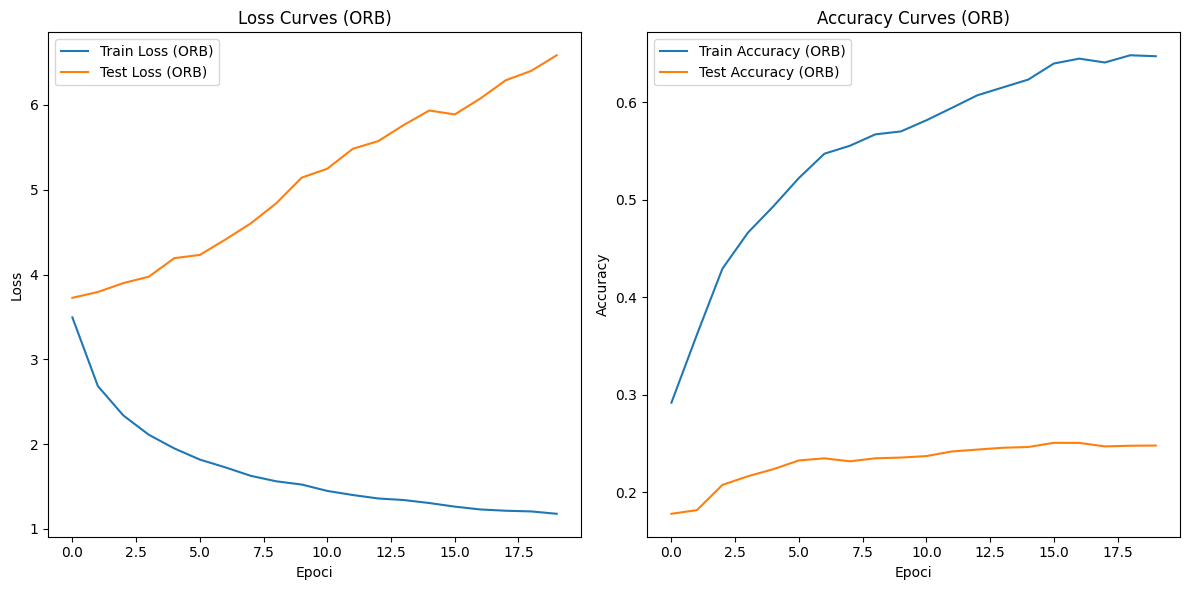

In [47]:
plt.figure(figsize=(12, 6))

# curba de loss
plt.subplot(1, 2, 1)
plt.plot(train_loss_curve_orb, label='Train Loss (ORB)')
plt.plot(test_loss_curve_orb, label='Test Loss (ORB)')
plt.title('Loss Curves (ORB)')
plt.xlabel('Epoci')
plt.ylabel('Loss')
plt.legend()

# curba de accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accuracy_curve_orb, label='Train Accuracy (ORB)')
plt.plot(test_accuracy_curve_orb, label='Test Accuracy (ORB)')
plt.title('Accuracy Curves (ORB)')
plt.xlabel('Epoci')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [81]:
# raport de clasificare pentru modelul MLP (ORB)
y_test_pred_orb = mlp_orb.predict(X_test_orb_filtered)
print("Raport de clasificare pentru modelul MLP (ORB)")
print(classification_report(y_test_orb_filtered, y_test_pred_orb))

Raport de clasificare pentru modelul MLP (ORB)
                       precision    recall  f1-score   support

              Apple 6       0.38      0.62      0.48        64
     Apple Braeburn 1       0.19      0.16      0.17       146
 Apple Crimson Snow 1       0.05      0.07      0.06       124
       Apple Golden 1       0.27      0.24      0.25       160
       Apple Golden 2       0.03      0.02      0.02        66
       Apple Golden 3       0.16      0.21      0.18        95
 Apple Granny Smith 1       0.03      0.02      0.03        48
    Apple Pink Lady 1       0.03      0.02      0.02        95
          Apple Red 1       0.07      0.03      0.04       154
          Apple Red 2       0.03      0.13      0.05        83
          Apple Red 3       0.15      0.05      0.08       129
Apple Red Delicious 1       0.05      0.07      0.06       153
   Apple Red Yellow 1       0.07      0.08      0.07       119
   Apple Red Yellow 2       0.07      0.17      0.10        64
       

II. Arhitectura de tip MLP direct peste imagini

In [49]:
path = X_train[0]
img = Image.open(path).convert('L')
img.size

(100, 100)

In [50]:
img_flat = np.array(img).flatten()
img_flat.shape

(10000,)

In [51]:
def load_images(image_paths, target_size=(32, 32)):
    images = []

    for path in image_paths:
        img = Image.open(path).convert('L')
        img = img.resize(target_size)
        images.append(np.array(img).flatten())

    return np.array(images)

In [52]:
X_train_img = load_images(X_train)
X_test_img = load_images(X_test)

In [53]:
X_train_img.shape

(70491, 1024)

In [54]:
# standardizarea datelor
scaler_flat = StandardScaler()
X_train_flat = scaler_flat.fit_transform(X_train_img)
X_test_flat = scaler_flat.transform(X_test_img)

In [55]:
# model MLP
class MLP(nn.Module):
    def __init__(self, num_classes=10):
        super(MLP, self).__init__()
        in_size = 1 * 32 * 32

        self.fc1 = nn.Linear(in_size, 256)
        self.fc2 = nn.Linear(256, 256)
        self.fc3 = nn.Linear(256, num_classes)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        x = x.view(-1, 1 * 32 * 32)

        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [56]:
num_classes = len(np.unique(y_train))
model = MLP(num_classes=num_classes)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# optimizator și funcție de pierdere
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [57]:
X_train_tensor = torch.tensor(X_train_flat, dtype=torch.float32).to(device)
X_test_tensor = torch.tensor(X_test_flat, dtype=torch.float32).to(device)

y_train_tensor = torch.tensor([CLASSES.index(label) for label in y_train], dtype=torch.long).to(device)
y_test_tensor = torch.tensor([CLASSES.index(label) for label in y_test], dtype=torch.long).to(device)

In [58]:
num_epochs = 20
batch_size = 64
train_loader = DataLoader(torch.utils.data.TensorDataset(X_train_tensor, y_train_tensor), batch_size=batch_size, shuffle=True)
test_loader = DataLoader(torch.utils.data.TensorDataset(X_test_tensor, y_test_tensor), batch_size=batch_size, shuffle=False)

In [59]:
train_accuracy_img = []
test_accuracy_img = []
train_loss_img = []
test_loss_img = []

start_time = time.time()

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()

    train_loss_img.append(running_loss / len(train_loader.dataset))
    train_accuracy_img.append(100.0 * correct / total)

    # evaluare pe setul de test
    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, targets in test_loader:
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            test_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

    test_loss_img.append(test_loss / len(test_loader.dataset))
    test_accuracy_img.append(100.0 * correct / total)

    print(f"Epoch {epoch + 1}/{num_epochs}, Train Loss: {train_loss_img[-1]:.4f}, Test Loss: {test_loss_img[-1]:.4f}, Train Acc: {train_accuracy_img[-1]:.2f}%, Test Acc: {test_accuracy_img[-1]:.2f}%")

end_time = time.time()

Epoch 1/20, Train Loss: 0.6600, Test Loss: 1.0773, Train Acc: 82.30%, Test Acc: 77.33%
Epoch 2/20, Train Loss: 0.0863, Test Loss: 1.0926, Train Acc: 97.52%, Test Acc: 80.49%
Epoch 3/20, Train Loss: 0.0654, Test Loss: 1.1375, Train Acc: 98.14%, Test Acc: 82.52%
Epoch 4/20, Train Loss: 0.0552, Test Loss: 1.3734, Train Acc: 98.42%, Test Acc: 79.66%
Epoch 5/20, Train Loss: 0.0491, Test Loss: 1.3216, Train Acc: 98.63%, Test Acc: 82.55%
Epoch 6/20, Train Loss: 0.0509, Test Loss: 1.5345, Train Acc: 98.62%, Test Acc: 83.04%
Epoch 7/20, Train Loss: 0.0521, Test Loss: 1.8430, Train Acc: 98.70%, Test Acc: 80.85%
Epoch 8/20, Train Loss: 0.0356, Test Loss: 1.6623, Train Acc: 99.15%, Test Acc: 83.68%
Epoch 9/20, Train Loss: 0.0568, Test Loss: 1.8477, Train Acc: 98.70%, Test Acc: 83.37%
Epoch 10/20, Train Loss: 0.0374, Test Loss: 2.4177, Train Acc: 99.21%, Test Acc: 79.93%
Epoch 11/20, Train Loss: 0.0381, Test Loss: 2.2490, Train Acc: 99.16%, Test Acc: 81.18%
Epoch 12/20, Train Loss: 0.0394, Test Los

In [60]:
training_time = end_time - start_time
print(f"Timpul total de antrenare pentru MLP (direct peste imagini): {training_time:.2f} secunde")

Timpul total de antrenare pentru MLP (direct peste imagini): 59.19 secunde


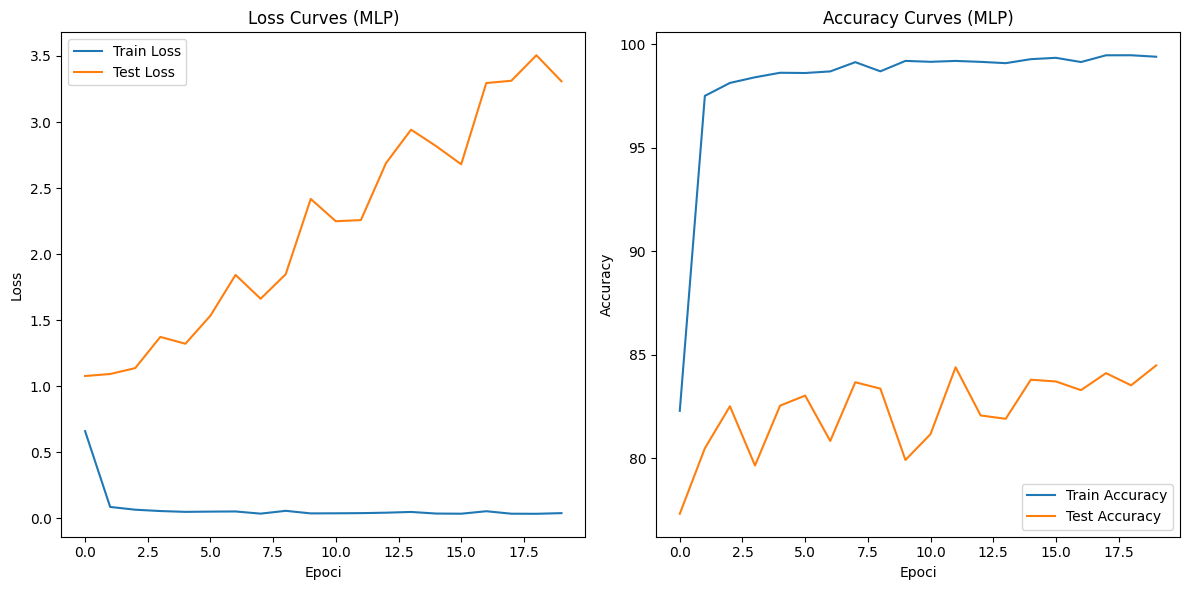

In [61]:
plt.figure(figsize=(12, 6))

# loss
plt.subplot(1, 2, 1)
plt.plot(train_loss_img, label='Train Loss')
plt.plot(test_loss_img, label='Test Loss')
plt.title('Loss Curves (MLP)')
plt.xlabel('Epoci')
plt.ylabel('Loss')
plt.legend()

# accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accuracy_img, label='Train Accuracy')
plt.plot(test_accuracy_img, label='Test Accuracy')
plt.title('Accuracy Curves (MLP)')
plt.xlabel('Epoci')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [62]:
# raport de clasificare pentru modelul MLP (direct peste imagini)
y_test_pred_img = []
model.eval()
with torch.no_grad():
    for inputs, _ in test_loader:
        outputs = model(inputs)
        _, predicted = outputs.max(1)
        y_test_pred_img.extend(predicted.cpu().numpy())

y_test_pred_img_labels = [CLASSES[pred] for pred in y_test_pred_img]

print("Raport de clasificare pentru modelul MLP direct peste imagini:")
print(classification_report(y_test, y_test_pred_img_labels))

Raport de clasificare pentru modelul MLP direct peste imagini:
                       precision    recall  f1-score   support

              Apple 6       0.92      1.00      0.96       157
     Apple Braeburn 1       0.67      0.72      0.69       164
 Apple Crimson Snow 1       0.95      0.81      0.88       148
       Apple Golden 1       0.80      0.71      0.75       160
       Apple Golden 2       0.89      0.90      0.90       164
       Apple Golden 3       0.90      0.96      0.93       161
 Apple Granny Smith 1       0.87      0.99      0.93       164
    Apple Pink Lady 1       0.86      0.63      0.73       152
          Apple Red 1       0.89      0.68      0.77       164
          Apple Red 2       0.85      0.68      0.76       164
          Apple Red 3       0.46      0.72      0.56       144
Apple Red Delicious 1       0.89      0.99      0.94       166
   Apple Red Yellow 1       0.90      0.99      0.94       164
   Apple Red Yellow 2       0.86      0.84      0.85  

III. Arhitectura de tip convolutional

In [63]:
# definire augmentari
augmentations = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.RandomResizedCrop((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5), (0.5,))
])

no_augmentations = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

In [64]:
class ImageDataset(torch.utils.data.Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert("L")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(CLASSES.index(label))

        return image, label

In [65]:
# crearea seturilor de date cu și fără augmentări
train_dataset_no_aug = ImageDataset(X_train, y_train, transform=no_augmentations)
train_dataset_aug = ImageDataset(X_train, y_train, transform=augmentations)
test_dataset = ImageDataset(X_test, y_test, transform=no_augmentations)

train_loader_no_aug = DataLoader(train_dataset_no_aug, batch_size=64, shuffle=True)
train_loader_aug = DataLoader(train_dataset_aug, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [66]:
print(len(np.unique(y_train)))
print(len(np.unique(y_test)))

141
141


In [67]:
class DeepConvNet(nn.Module):
    def __init__(self, num_classes=np.unique(y_train)):
        super(DeepConvNet, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=7, stride=2, padding=3)
        self.bn1 = nn.BatchNorm2d(16)
        self.relu = nn.ReLU()

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1)
        self.bn2 = nn.BatchNorm2d(32)

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1)
        self.bn3 = nn.BatchNorm2d(64)

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(64, num_classes)

    def forward(self, x):

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu(x)

        x = self.conv3(x)
        x = self.bn3(x)
        x = self.relu(x)

        x = self.global_pool(x)
        # x = torch.flatten(x, 1)
        # x = x.view(-1, x.size(0))
        x = x.view(x.size(0), -1)

        x = self.dropout(x)
        x = self.fc(x)

        return x

In [68]:
def train_model(model, train_loader, test_loader, num_epochs=20):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    train_losses = []
    test_losses = []
    train_accuracies = []
    test_accuracies = []

    start_time = time.time()

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        correct = 0
        total = 0

        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

        train_losses.append(train_loss / len(train_loader.dataset))
        train_accuracies.append(100.0 * correct / total)

        model.eval()
        test_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():
            for inputs, targets in test_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)

                test_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                total += targets.size(0)
                correct += predicted.eq(targets).sum().item()

        test_losses.append(test_loss / len(test_loader.dataset))
        test_accuracies.append(100.0 * correct / total)

        print(f"Epoch {epoch + 1}/{num_epochs}, Train Loss: {train_losses[-1]:.4f}, Test Loss: {test_losses[-1]:.4f}, Train Acc: {train_accuracies[-1]:.2f}%, Test Acc: {test_accuracies[-1]:.2f}%")

    end_time = time.time()
    training_time = end_time - start_time

    print(f"\n\nTimpul total de antrenare: {training_time:.2f} secunde")

    return train_losses, test_losses, train_accuracies, test_accuracies

In [69]:
model_no_aug = DeepConvNet(num_classes=len(np.unique(y_train)))
train_losses_no_aug, test_losses_no_aug, train_accuracies_no_aug, test_accuracies_no_aug = train_model(model_no_aug, train_loader_no_aug, test_loader)

Epoch 1/20, Train Loss: 2.9919, Test Loss: 1.8609, Train Acc: 25.63%, Test Acc: 57.97%
Epoch 2/20, Train Loss: 1.6360, Test Loss: 1.2159, Train Acc: 52.91%, Test Acc: 71.26%
Epoch 3/20, Train Loss: 1.2457, Test Loss: 1.0508, Train Acc: 62.89%, Test Acc: 73.05%
Epoch 4/20, Train Loss: 1.0561, Test Loss: 0.9384, Train Acc: 67.84%, Test Acc: 75.68%
Epoch 5/20, Train Loss: 0.9342, Test Loss: 0.8177, Train Acc: 71.19%, Test Acc: 78.78%
Epoch 6/20, Train Loss: 0.8395, Test Loss: 0.7708, Train Acc: 73.71%, Test Acc: 79.57%
Epoch 7/20, Train Loss: 0.7759, Test Loss: 0.7251, Train Acc: 75.72%, Test Acc: 80.76%
Epoch 8/20, Train Loss: 0.7211, Test Loss: 0.6961, Train Acc: 77.27%, Test Acc: 81.02%
Epoch 9/20, Train Loss: 0.6753, Test Loss: 0.6587, Train Acc: 78.78%, Test Acc: 82.94%
Epoch 10/20, Train Loss: 0.6419, Test Loss: 0.6629, Train Acc: 79.84%, Test Acc: 82.48%
Epoch 11/20, Train Loss: 0.6018, Test Loss: 0.6238, Train Acc: 81.02%, Test Acc: 83.38%
Epoch 12/20, Train Loss: 0.5749, Test Los

In [70]:
model_aug = DeepConvNet(num_classes=len(np.unique(y_train)))
train_losses_aug, test_losses_aug, train_accuracies_aug, test_accuracies_aug = train_model(model_aug, train_loader_aug, test_loader)

Epoch 1/20, Train Loss: 3.7484, Test Loss: 3.3150, Train Acc: 10.96%, Test Acc: 15.17%
Epoch 2/20, Train Loss: 2.8912, Test Loss: 2.8223, Train Acc: 24.67%, Test Acc: 20.83%
Epoch 3/20, Train Loss: 2.5709, Test Loss: 2.2269, Train Acc: 31.52%, Test Acc: 37.06%
Epoch 4/20, Train Loss: 2.4198, Test Loss: 2.3400, Train Acc: 34.83%, Test Acc: 32.09%
Epoch 5/20, Train Loss: 2.3263, Test Loss: 1.9983, Train Acc: 36.91%, Test Acc: 39.29%
Epoch 6/20, Train Loss: 2.2551, Test Loss: 2.2761, Train Acc: 38.74%, Test Acc: 32.63%
Epoch 7/20, Train Loss: 2.1831, Test Loss: 1.9497, Train Acc: 40.53%, Test Acc: 41.36%
Epoch 8/20, Train Loss: 2.1265, Test Loss: 1.9005, Train Acc: 41.53%, Test Acc: 44.20%
Epoch 9/20, Train Loss: 2.0844, Test Loss: 1.8943, Train Acc: 42.60%, Test Acc: 42.18%
Epoch 10/20, Train Loss: 2.0458, Test Loss: 1.8416, Train Acc: 43.63%, Test Acc: 45.07%
Epoch 11/20, Train Loss: 2.0006, Test Loss: 1.9114, Train Acc: 44.57%, Test Acc: 43.38%
Epoch 12/20, Train Loss: 1.9732, Test Los

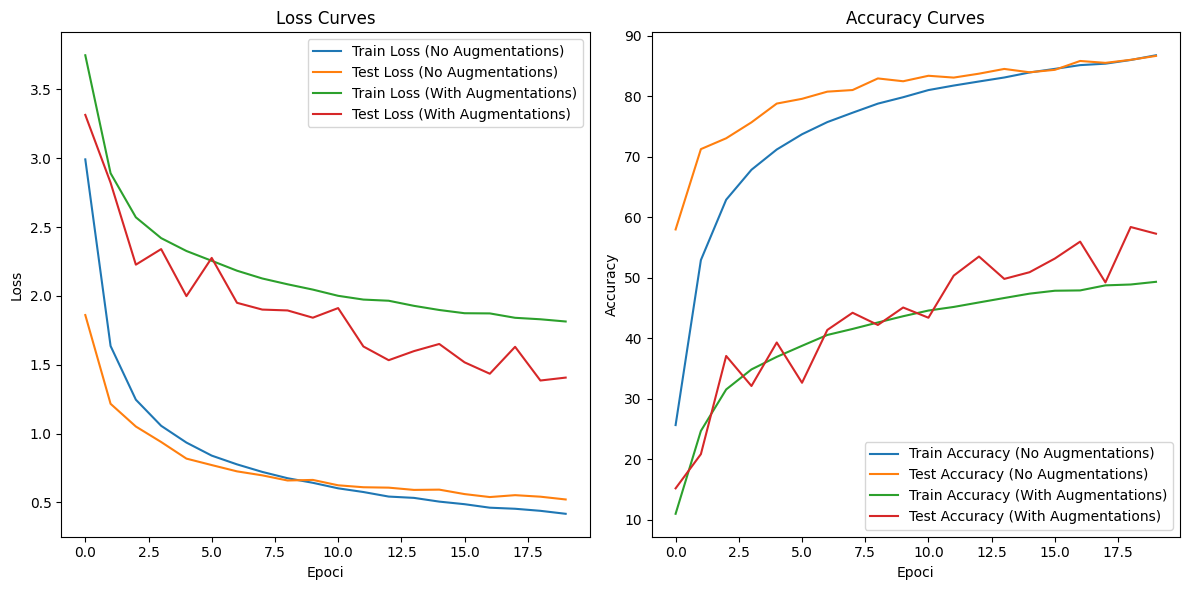

In [71]:
plt.figure(figsize=(12, 6))

# loss
plt.subplot(1, 2, 1)
plt.plot(train_losses_no_aug, label='Train Loss (No Augmentations)')
plt.plot(test_losses_no_aug, label='Test Loss (No Augmentations)')
plt.plot(train_losses_aug, label='Train Loss (With Augmentations)')
plt.plot(test_losses_aug, label='Test Loss (With Augmentations)')
plt.title('Loss Curves')
plt.xlabel('Epoci')
plt.ylabel('Loss')
plt.legend()

# accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accuracies_no_aug, label='Train Accuracy (No Augmentations)')
plt.plot(test_accuracies_no_aug, label='Test Accuracy (No Augmentations)')
plt.plot(train_accuracies_aug, label='Train Accuracy (With Augmentations)')
plt.plot(test_accuracies_aug, label='Test Accuracy (With Augmentations)')
plt.title('Accuracy Curves')
plt.xlabel('Epoci')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [79]:
# raport de clasificare pentru modelul fără augmentări
model_no_aug.eval()
all_targets_no_aug = []
all_predictions_no_aug = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model_no_aug(inputs)
        _, predicted = outputs.max(1)
        all_targets_no_aug.extend(targets.cpu().numpy())
        all_predictions_no_aug.extend(predicted.cpu().numpy())

print("Raport de clasificare pentru modelul fără augmentări")
print(classification_report(all_targets_no_aug, all_predictions_no_aug, target_names=CLASSES, zero_division=0))

Raport de clasificare pentru modelul fără augmentări
                       precision    recall  f1-score   support

         Cantaloupe 1       1.00      1.00      1.00       164
         Grape Blue 1       0.84      1.00      0.91       328
              Lemon 1       1.00      0.74      0.85       164
           Eggplant 1       0.62      0.65      0.63       156
          Onion Red 1       0.43      0.69      0.53       150
        Grape White 3       1.00      1.00      1.00       164
       Pear Forelle 1       0.85      0.98      0.91       234
      Cucumber Ripe 2       0.98      0.71      0.82       156
              Dates 1       0.85      0.70      0.77       166
              Apple 6       0.77      1.00      0.87       157
       Apple Golden 3       0.87      1.00      0.93       161
       Potato Sweet 1       0.71      0.34      0.46       150
            Avocado 1       0.88      1.00      0.93       143
         Pepper Red 1       0.65      0.96      0.78       222
 

In [78]:
# raport de clasificare pentru modelul cu augmentări
model_aug.eval()
all_targets_aug = []
all_predictions_aug = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model_aug(inputs)
        _, predicted = outputs.max(1)
        all_targets_aug.extend(targets.cpu().numpy())
        all_predictions_aug.extend(predicted.cpu().numpy())

# all_test_pred_labels = [CLASSES[pred] for pred in all_predictions_aug]

print("Raport de clasificare pentru modelul cu augmentări")
print(classification_report(all_targets_aug, all_predictions_aug, target_names=CLASSES, zero_division=0))

Raport de clasificare pentru modelul cu augmentări
                       precision    recall  f1-score   support

         Cantaloupe 1       0.99      1.00      0.99       164
         Grape Blue 1       0.96      0.94      0.95       328
              Lemon 1       0.62      0.53      0.57       164
           Eggplant 1       0.21      0.81      0.34       156
          Onion Red 1       0.00      0.00      0.00       150
        Grape White 3       0.99      0.99      0.99       164
       Pear Forelle 1       0.35      0.65      0.46       234
      Cucumber Ripe 2       0.90      0.95      0.92       156
              Dates 1       0.23      0.27      0.25       166
              Apple 6       1.00      0.94      0.97       157
       Apple Golden 3       0.82      0.58      0.68       161
       Potato Sweet 1       0.23      0.35      0.27       150
            Avocado 1       0.32      0.58      0.41       143
         Pepper Red 1       0.79      0.14      0.23       222
   